# Quantum GNN on QM9: Phases 3–5 (Training, Ablations, Robustness)

`QGNN_02_QuantumGNN.ipynb` built the circuit and showed that it is correct and can learn. This notebook trains it properly and asks what it actually learns.

| Phase | Question | Section |
|---|---|---|
| 3. Model selection | Which depth (L = 1–4) and how many encoding angles per qubit (1 or 2)? Chosen on **validation** MAE only | 2 |
| 4. Ablations | Does entanglement help? Does bond type matter? Does putting the graph into the circuit help, compared with a plain circuit on 8 PCA features? Does a classical model with the same ~75 parameters do as well? | 3 |
| 5. Robustness | 3 seeds on the random split, 3 seeds on the scaffold split, and errors on fluorine molecules | 4 |

The model code lives in `qgnn_lib.py`. It is the same circuit and fast simulator as in notebook 02, plus switches for the ablations, a ~75-parameter classical twin, and a training loop. Training uses single precision (`float32` / `complex64`), which is about 3× faster than double precision; notebook 02 already checked the simulator against PennyLane in double precision.

**Training setup (all runs):** Adam on MSE of the scaled target, batch 128, learning rate 0.01 halved when validation stops improving, early stopping on validation MAE (eV), weights restored from the best epoch. The test set is used only after every choice is fixed.

All results are saved to `results/quantum_results.csv` for the final comparison with the classical GNNs.

## 0. Setup

In [1]:
import os, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

torch.set_default_dtype(torch.float32)
import qgnn_lib as Q
Q.CDTYPE = torch.complex64

torch.set_num_threads(max(1, (os.cpu_count() or 2) // 2))   # leave cores free for other work
print("torch", torch.__version__, "| threads", torch.get_num_threads())

torch 2.14.1+cu130 | threads 1


In [2]:
GRAPH_DIR = os.path.join("processed", "graphs")
RES_DIR   = "results"
os.makedirs(RES_DIR, exist_ok=True)

EPOCHS   = 25      # max epochs per run (early stopping usually ends sooner); raise on a faster machine
PATIENCE = 5
LR       = 0.01
BATCH    = 128
SEEDS    = [0, 1, 2]

meta = json.load(open(os.path.join(GRAPH_DIR, "qm9_gap_subset_meta.json")))
Y_MEAN, Y_STD = meta["y_mean_eV"], meta["y_std_eV"]
data, split = Q.load_qgnn_arrays(os.path.join(GRAPH_DIR, "qm9_gap_subset_qgnn.npz"))
index = pd.read_csv(os.path.join(GRAPH_DIR, "qm9_gap_subset_index.csv"), index_col="sub_idx")
print({k: len(v) for k, v in split.items()})

RESULTS = []          # one row per trained model
HISTORIES = {}        # learning curves

def run(name, make_model, split_name="random", seed=0, data_=None, log=True):
    # Train one model, evaluate on val and test, store the result
    d = data_ if data_ is not None else data
    torch.manual_seed(seed)
    model = make_model()
    tr, va, te = (split[f"{split_name}_{s}"] for s in ("train", "val", "test"))
    print(f"[{name} | {split_name} | seed {seed}] {Q.count_params(model)} parameters")
    model, hist = Q.train(model, d, tr, va, Y_STD, epochs=EPOCHS, lr=LR, batch=BATCH,
                          patience=PATIENCE, seed=seed, verbose=log)
    pred_te = Q.predict(model, d, te)
    err = (pred_te - d["y"][te]).abs() * Y_STD
    has_F = torch.tensor(index["n_F"].values[te.numpy()] > 0)
    row = {"model": name, "split": split_name, "seed": seed, "params": Q.count_params(model),
           "val_mae_eV": hist["best_val_mae"], "test_mae_eV": err.mean().item(),
           "test_mae_F_eV": err[has_F].mean().item(), "test_mae_noF_eV": err[~has_F].mean().item(),
           "epochs": len(hist["epoch"]), "train_time_s": hist["train_time_s"]}
    RESULTS.append(row); HISTORIES[(name, split_name, seed)] = hist
    print(f"  -> val {row['val_mae_eV']:.3f} eV | test {row['test_mae_eV']:.3f} eV | "
          f"{row['epochs']} epochs, {row['train_time_s']:.0f}s")
    return model, row, pred_te

def results_table(rows=None):
    return pd.DataFrame(rows if rows is not None else RESULTS)

{'random_train': 10000, 'random_val': 2000, 'random_test': 2000, 'scaffold_train': 10000, 'scaffold_val': 2000, 'scaffold_test': 2000}


## 1. Two trivial baselines

Any model has to beat these to be worth anything:

- **Mean predictor:** always predicts the average training gap.
- **Linear regression on the mean atom features:** average the 23 atom features over each molecule and fit a linear model. This uses no bonds and no quantum circuit.

In [3]:
tr, te = split["random_train"], split["random_test"]
y = data["y"]
mean_mae = (y[te] - y[tr].mean()).abs().mean().item() * Y_STD

m = data["mask"].float()[..., None]
F = (data["X"] * m).sum(1) / m.sum(1)                          # mean atom features [N, 23]
A = torch.cat([F, torch.ones(len(F), 1)], 1)
w = torch.linalg.lstsq(A[tr], y[tr][:, None]).solution
lin_mae = (A[te] @ w - y[te][:, None]).abs().mean().item() * Y_STD

baselines = pd.DataFrame([
    {"model": "Mean predictor", "params": 1, "test_mae_eV": mean_mae},
    {"model": "Linear on mean atom features", "params": A.shape[1], "test_mae_eV": lin_mae},
])
baselines.round(3)

,model,params,test_mae_eV
0,Mean predictor,1,1.067
1,Linear on mean atom features,24,0.497


## 2. Phase 3: model selection (random split, seed 0)

First the depth, L = 1, 2, 3, 4, with two angles per qubit (RY and RZ). Then the best depth with only one angle (RY). The choice is made on **validation** MAE.

In [4]:
sweep = []
for L in [1, 2, 3, 4]:
    _, row, _ = run(f"QGNN L={L}, 2 angles", lambda L=L: Q.QGNN(n_layers=L, n_angles=2), log=False)
    sweep.append(row | {"L": L, "angles": 2})

best_L = min(sweep, key=lambda r: r["val_mae_eV"])["L"]
_, row, _ = run(f"QGNN L={best_L}, 1 angle", lambda: Q.QGNN(n_layers=best_L, n_angles=1), log=False)
sweep.append(row | {"L": best_L, "angles": 1})

sweep_df = pd.DataFrame(sweep)[["L", "angles", "params", "val_mae_eV", "test_mae_eV", "epochs", "train_time_s"]]
best = sweep_df.sort_values("val_mae_eV").iloc[0]
BEST_L, BEST_ANGLES = int(best["L"]), int(best["angles"])
print(f"Selected on validation: L = {BEST_L}, {BEST_ANGLES} angle(s) per qubit")
sweep_df.round(3)

[QGNN L=1, 2 angles | random | seed 0] 57 parameters


  -> val 0.458 eV | test 0.459 eV | 25 epochs, 40s
[QGNN L=2, 2 angles | random | seed 0] 63 parameters


  -> val 0.467 eV | test 0.459 eV | 25 epochs, 77s
[QGNN L=3, 2 angles | random | seed 0] 69 parameters


  -> val 0.427 eV | test 0.426 eV | 25 epochs, 115s
[QGNN L=4, 2 angles | random | seed 0] 75 parameters


  -> val 0.377 eV | test 0.379 eV | 25 epochs, 153s
[QGNN L=4, 1 angle | random | seed 0] 51 parameters


  -> val 0.455 eV | test 0.449 eV | 25 epochs, 148s
Selected on validation: L = 4, 2 angle(s) per qubit


,L,angles,params,val_mae_eV,test_mae_eV,epochs,train_time_s
0,1,2,57,0.458,0.459,25,40.482
1,2,2,63,0.467,0.459,25,77.240
2,3,2,69,0.427,0.426,25,114.588
3,4,2,75,0.377,0.379,25,153.253
4,4,1,51,0.455,0.449,25,147.575


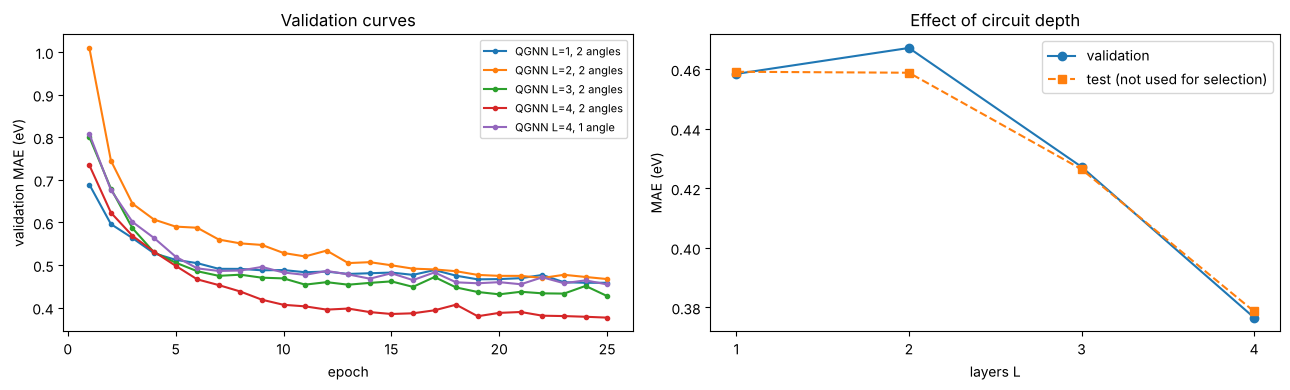

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for (name, sp, seed), h in HISTORIES.items():
    if sp == "random" and seed == 0 and name.startswith("QGNN L="):
        axes[0].plot(h["epoch"], h["val_mae"], marker=".", label=name)
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("validation MAE (eV)"); axes[0].set_title("Validation curves")
axes[0].legend(fontsize=8)
s2 = sweep_df[sweep_df.angles == 2]
axes[1].plot(s2["L"], s2["val_mae_eV"], "o-", label="validation")
axes[1].plot(s2["L"], s2["test_mae_eV"], "s--", label="test (not used for selection)")
axes[1].set_xlabel("layers L"); axes[1].set_ylabel("MAE (eV)"); axes[1].set_title("Effect of circuit depth")
axes[1].set_xticks([1, 2, 3, 4]); axes[1].legend()
plt.tight_layout(); plt.show()

## 3. Phase 4: ablations (random split, seed 0, selected depth)

| Ablation | What changes | What it tests |
|---|---|---|
| **No entanglement** | every ZZ gate removed; each qubit evolves on its own | Is entanglement doing any work? |
| **Bond-type blind** | one ZZ weight for all bond types instead of one per type | Does the circuit use bond chemistry? |
| **Plain circuit on 8 PCA features** | no graph: 8 qubits encode the 8 PCA angles from preprocessing, fixed ring of ZZ gates | Does building the graph into the circuit help? |
| **Classical twin (~79 parameters)** | a tiny classical message-passing network with the same inputs, mean readout and about the same number of parameters | Quantum vs classical at equal size |

In [6]:
make_best = lambda **kw: (lambda: Q.QGNN(n_layers=BEST_L, n_angles=BEST_ANGLES, **kw))
best_name = f"QGNN L={BEST_L}, {BEST_ANGLES} angle{'s' if BEST_ANGLES == 2 else ''}"

def no_entangle():
    m = make_best()(); m.entangle = False
    m.w_zz.requires_grad_(False)          # unused weights are not counted as parameters
    return m

abl = []
abl.append(next(r for r in RESULTS if r["model"] == best_name and r["seed"] == 0) | {"ablation": "full model"})
abl.append(run("QGNN no entanglement", no_entangle, log=False)[1] | {"ablation": "no entanglement"})
abl.append(run("QGNN bond-type blind", make_best(bond_blind=True), log=False)[1] | {"ablation": "bond-type blind"})

[QGNN no entanglement | random | seed 0] 59 parameters


  -> val 0.543 eV | test 0.535 eV | 20 epochs, 114s
[QGNN bond-type blind | random | seed 0] 63 parameters


  -> val 0.406 eV | test 0.409 eV | 25 epochs, 152s


In [7]:
# Plain (non-graph) circuit on the 8 PCA angles saved by the preprocessing notebook
proc = np.load(os.path.join("processed", "qm9_gap_eV_processed.npz"))
row_to_q = {}
for part in ["tr", "va", "te"]:
    for r, qa in zip(proc[f"idx_{part}"], proc[f"Q_{part}"]):
        row_to_q[int(r)] = qa
Q8 = torch.tensor(np.stack([row_to_q[int(r)] for r in data["row"]]), dtype=torch.float32)   # [14000, 8], in [0, pi]

ring = torch.zeros(8, 8, dtype=torch.long)
for i in range(8):
    ring[i, (i + 1) % 8] = ring[(i + 1) % 8, i] = 1                # fixed ring of ZZ gates
data_pca = {"X": Q8[..., None], "bonds": ring.expand(len(Q8), 8, 8).clone(),
            "mask": torch.ones(len(Q8), 8, dtype=torch.bool), "y": data["y"], "y_eV": data["y_eV"]}

abl.append(run("Plain circuit, 8 PCA angles",
               lambda: Q.QGNN(n_layers=BEST_L, node_dim=1, n_qubits=8, n_angles=BEST_ANGLES, n_bond_types=1),
               data_=data_pca, log=False)[1] | {"ablation": "no graph (8 PCA angles)"})
abl.append(run("Classical twin (TinyGNN)", lambda: Q.TinyGNN(), log=False)[1] | {"ablation": "classical, same size"})

abl_df = pd.DataFrame(abl)[["ablation", "model", "params", "val_mae_eV", "test_mae_eV", "train_time_s"]]
abl_df.round(3)

[Plain circuit, 8 PCA angles | random | seed 0] 19 parameters


  -> val 0.839 eV | test 0.839 eV | 25 epochs, 80s
[Classical twin (TinyGNN) | random | seed 0] 79 parameters


  -> val 0.405 eV | test 0.406 eV | 25 epochs, 4s


,ablation,model,params,val_mae_eV,test_mae_eV,train_time_s
0,full model,"QGNN L=4, 2 angles",75,0.377,0.379,153.253
1,no entanglement,QGNN no entanglement,59,0.543,0.535,114.463
2,bond-type blind,QGNN bond-type blind,63,0.406,0.409,151.990
3,no graph (8 PCA angles),"Plain circuit, 8 PCA angles",19,0.839,0.839,80.432
4,"classical, same size",Classical twin (TinyGNN),79,0.405,0.406,3.587


## 4. Phase 5: robustness (3 seeds, random and scaffold splits)

The selected QGNN and the classical twin are trained with 3 seeds on each split. The scaffold test set contains ring systems that never appear in training, so the gap between the two splits shows how well each model generalises to new chemistry.

In [8]:
for sp in ["random", "scaffold"]:
    for seed in SEEDS:
        if not any(r["model"] == best_name and r["split"] == sp and r["seed"] == seed for r in RESULTS):
            run(best_name, make_best(), split_name=sp, seed=seed, log=False)
        if not any(r["model"] == "Classical twin (TinyGNN)" and r["split"] == sp and r["seed"] == seed for r in RESULTS):
            run("Classical twin (TinyGNN)", lambda: Q.TinyGNN(), split_name=sp, seed=seed, log=False)

[QGNN L=4, 2 angles | random | seed 1] 75 parameters


  -> val 0.416 eV | test 0.419 eV | 25 epochs, 148s
[Classical twin (TinyGNN) | random | seed 1] 79 parameters


  -> val 0.444 eV | test 0.445 eV | 25 epochs, 3s
[QGNN L=4, 2 angles | random | seed 2] 75 parameters


  -> val 0.410 eV | test 0.403 eV | 24 epochs, 144s
[Classical twin (TinyGNN) | random | seed 2] 79 parameters


  -> val 0.411 eV | test 0.409 eV | 25 epochs, 3s
[QGNN L=4, 2 angles | scaffold | seed 0] 75 parameters


...

  -> val 0.454 eV | test 0.466 eV | 23 epochs, 3s
[QGNN L=4, 2 angles | scaffold | seed 1] 75 parameters


  -> val 0.481 eV | test 0.499 eV | 23 epochs, 139s
[Classical twin (TinyGNN) | scaffold | seed 1] 79 parameters


  -> val 0.460 eV | test 0.487 eV | 22 epochs, 3s
[QGNN L=4, 2 angles | scaffold | seed 2] 75 parameters


  -> val 0.432 eV | test 0.454 eV | 15 epochs, 89s
[Classical twin (TinyGNN) | scaffold | seed 2] 79 parameters


  -> val 0.441 eV | test 0.461 eV | 25 epochs, 3s


In [9]:
res = results_table()
rob = res[res.model.isin([best_name, "Classical twin (TinyGNN)"])]
summary = (rob.groupby(["model", "split"])
              .agg(params=("params", "first"), seeds=("seed", "count"),
                   test_mae=("test_mae_eV", "mean"), test_std=("test_mae_eV", "std"),
                   mae_with_F=("test_mae_F_eV", "mean"), mae_without_F=("test_mae_noF_eV", "mean"),
                   time_s=("train_time_s", "mean"))
              .round(3))
summary

params  seeds  test_mae  test_std  \
model                    split                                         
Classical twin (TinyGNN) random        79      3     0.420     0.022   
                         scaffold      79      3     0.471     0.014   
QGNN L=4, 2 angles       random        75      3     0.400     0.020   
                         scaffold      75      3     0.468     0.027   

                                   mae_with_F  mae_without_F   time_s  
model                    split                                         
Classical twin (TinyGNN) random         0.495          0.419    3.466  
                         scaffold       0.920          0.471    3.329  
QGNN L=4, 2 angles       random         0.467          0.399  148.371  
                         scaffold       0.987          0.468  126.425

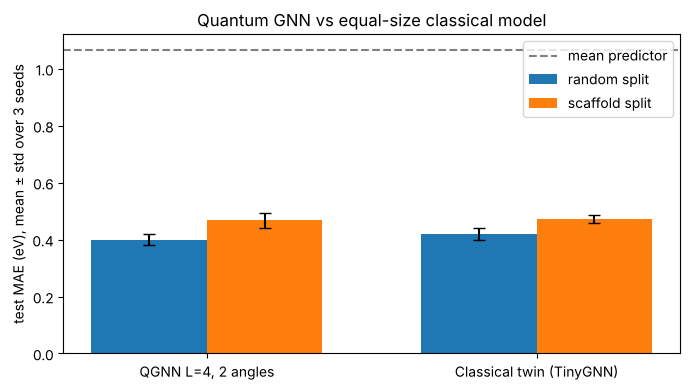

In [10]:
fig, ax = plt.subplots(figsize=(7, 4))
models = [best_name, "Classical twin (TinyGNN)"]
xs = np.arange(len(models)); w = 0.35
for k, sp in enumerate(["random", "scaffold"]):
    vals = [summary.loc[(m, sp), "test_mae"] for m in models]
    errs = [summary.loc[(m, sp), "test_std"] for m in models]
    ax.bar(xs + (k - 0.5) * w, vals, w, yerr=errs, capsize=4, label=f"{sp} split")
ax.axhline(mean_mae, color="grey", ls="--", label="mean predictor")
ax.set_xticks(xs); ax.set_xticklabels(models); ax.set_ylabel("test MAE (eV), mean ± std over 3 seeds")
ax.set_title("Quantum GNN vs equal-size classical model"); ax.legend()
plt.tight_layout(); plt.show()

## 5. Save results

In [11]:
res = results_table()
res.to_csv(os.path.join(RES_DIR, "quantum_results.csv"), index=False)
baselines.to_csv(os.path.join(RES_DIR, "trivial_baselines.csv"), index=False)
json.dump({"best_L": BEST_L, "best_angles": BEST_ANGLES, "best_name": best_name,
           "epochs_max": EPOCHS, "patience": PATIENCE, "lr": LR, "batch": BATCH},
          open(os.path.join(RES_DIR, "quantum_config.json"), "w"), indent=2)
print(f"{len(res)} runs saved to {RES_DIR}/quantum_results.csv")
res.round(3)

19 runs saved to results/quantum_results.csv


,model,split,seed,params,val_mae_eV,test_mae_eV,test_mae_F_eV,test_mae_noF_eV,epochs,train_time_s
0,"QGNN L=1, 2 angles",random,0,57,0.458,0.459,0.653,0.457,25,40.482
1,"QGNN L=2, 2 angles",random,0,63,0.467,0.459,0.501,0.458,25,77.240
2,"QGNN L=3, 2 angles",random,0,69,0.427,0.426,0.527,0.425,25,114.588
3,"QGNN L=4, 2 angles",random,0,75,0.377,0.379,0.459,0.378,25,153.253
4,"QGNN L=4, 1 angle",random,0,51,0.455,0.449,0.509,0.448,25,147.575
5,QGNN no entanglement,random,0,59,0.543,0.535,0.637,0.533,20,114.463
6,QGNN bond-type blind,random,0,63,0.406,0.409,0.552,0.407,25,151.990
7,"Plain circuit, 8 PCA angles",random,0,19,0.839,0.839,1.248,0.833,25,80.432
8,Classical twin (TinyGNN),random,0,79,0.405,0.406,0.474,0.405,25,3.587
9,"QGNN L=4, 2 angles",random,1,75,0.416,0.419,0.490,0.418,25,148.337


## 6. Reading the results

The numbers above are produced by this run; the summary below reads them programmatically so it always matches.

In [12]:
r = results_table()
def mean_of(name, sp="random"):
    return r[(r.model == name) & (r.split == sp)]["test_mae_eV"].mean()

full, noent = mean_of(best_name), r[r.model == "QGNN no entanglement"]["test_mae_eV"].iloc[0]
blind = r[r.model == "QGNN bond-type blind"]["test_mae_eV"].iloc[0]
pca = r[r.model == "Plain circuit, 8 PCA angles"]["test_mae_eV"].iloc[0]
twin = mean_of("Classical twin (TinyGNN)")
lines = [
    f"Selected QGNN ({best_name}, {r[r.model == best_name]['params'].iloc[0]} params): "
    f"test MAE {full:.3f} eV (random, mean of 3 seeds), {mean_of(best_name, 'scaffold'):.3f} eV (scaffold).",
    f"Baselines: mean predictor {mean_mae:.3f} eV, linear on mean atom features {lin_mae:.3f} eV.",
    f"Removing entanglement: {noent:.3f} eV ({'worse' if noent > full else 'not worse'} by {abs(noent - full):.3f} eV, seed 0 vs 3-seed mean).",
    f"One ZZ weight for all bond types: {blind:.3f} eV.",
    f"Plain 8-qubit circuit without the graph: {pca:.3f} eV.",
    f"Classical twin with {r[r.model == 'Classical twin (TinyGNN)']['params'].iloc[0]} params: {twin:.3f} eV (random), "
    f"{mean_of('Classical twin (TinyGNN)', 'scaffold'):.3f} eV (scaffold).",
]
print("\n".join("• " + l for l in lines))

• Selected QGNN (QGNN L=4, 2 angles, 75 params): test MAE 0.400 eV (random, mean of 3 seeds), 0.468 eV (scaffold).
• Baselines: mean predictor 1.067 eV, linear on mean atom features 0.497 eV.
• Removing entanglement: 0.535 eV (worse by 0.135 eV, seed 0 vs 3-seed mean).
• One ZZ weight for all bond types: 0.409 eV.
• Plain 8-qubit circuit without the graph: 0.839 eV.
• Classical twin with 79 params: 0.420 eV (random), 0.471 eV (scaffold).
